# Lab 4 Task 4: Controlled Channel Experiments

Analyze four independent PN captures at each of three successfully acquired TX gains. Calculate coherent and magnitude averages, strength factors, and a gain-response regression.


In [5]:
from pathlib import Path
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

def locate_lab_root():
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / "support" / "lab4_tools.py").is_file():
            return base
    raise FileNotFoundError("Open this notebook from its Lab 4 folder.")

LAB_ROOT = locate_lab_root()
sys.path.insert(0, str(LAB_ROOT / "support"))
WORK_DIR = LAB_ROOT / "work"
FIGURE_DIR = WORK_DIR / "figures"
WAVEFORM_DIR = WORK_DIR / "waveforms"
CAPTURE_DIR = Path(os.environ.get("ECE7377_LAB4_CAPTURE_DIR", WORK_DIR / "captures"))
for path in (FIGURE_DIR, WAVEFORM_DIR, CAPTURE_DIR):
    path.mkdir(parents=True, exist_ok=True)
print("Lab root:", LAB_ROOT)
print("Capture directory:", CAPTURE_DIR)


Lab root: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab4
Capture directory: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab4/work/captures


## Load and validate all captures


In [2]:
from lab4_tools import analyze_gain_sweep, plot_gain_sweep

gains = np.array([25, 32, 40])
runs = (1, 2, 3, 4)
result = analyze_gain_sweep(CAPTURE_DIR, gains=gains, runs=runs)
print("Loaded", len(result["records"]), "real captures")
for record in result["records"]:
    print(
        f"gain {record['tx_gain_db']:2d}, run {record['run']}: "
        f"|h|={record['channel_magnitude']:.8g}, "
        f"CFO={record['cfo_hz']:.2f} Hz, "
        f"EVM={100*record['evm']:.2f}%, CER={record['chip_error_rate']:.6f}"
    )


Loaded 12 real captures
gain 25, run 1: |h|=0.0076320056, CFO=134.87 Hz, EVM=44.24%, CER=0.000000
gain 25, run 2: |h|=0.0082823194, CFO=98.95 Hz, EVM=16.98%, CER=0.000000
gain 25, run 3: |h|=0.0082236939, CFO=118.20 Hz, EVM=20.28%, CER=0.000000
gain 25, run 4: |h|=0.0081891446, CFO=94.29 Hz, EVM=21.50%, CER=0.000000
gain 32, run 1: |h|=0.017117579, CFO=130.94 Hz, EVM=44.25%, CER=0.000000
gain 32, run 2: |h|=0.017728959, CFO=121.97 Hz, EVM=33.26%, CER=0.000000
gain 32, run 3: |h|=0.015542812, CFO=69.62 Hz, EVM=66.43%, CER=0.000000
gain 32, run 4: |h|=0.01695216, CFO=122.61 Hz, EVM=46.50%, CER=0.000000
gain 40, run 1: |h|=0.047935229, CFO=144.41 Hz, EVM=78.51%, CER=0.000000
gain 40, run 2: |h|=0.050741665, CFO=141.52 Hz, EVM=67.37%, CER=0.000000
gain 40, run 3: |h|=0.043021428, CFO=146.92 Hz, EVM=100.93%, CER=0.014663
gain 40, run 4: |h|=0.041325667, CFO=58.33 Hz, EVM=108.95%, CER=0.026393


<span style="color:#165696"><b>Report.</b> For every condition, report all four complex estimates h, |h|, CFO, EVM, chip error rate, and correlation metric. </span>

In [7]:
records_df = pd.DataFrame([
    {
        "TX Gain (dB)": record["tx_gain_db"],
        "Run": record["run"],
        "Complex Channel Estimate h": record["channel"],
        "|h|": record["channel_magnitude"],
        "CFO (Hz)": record["cfo_hz"],
        "EVM (%)": 100 * record["evm"],
        "Chip Error Rate": record["chip_error_rate"],
        "Correlation (dB)": record["peak_to_median_db"],
    }
    for record in result["records"]
])

display(records_df.round({"|h|": 6, "CFO (Hz)": 2, "EVM (%)": 2, "Chip Error Rate": 6, "Correlation (dB)": 2}))

,TX Gain (dB),Run,Complex Channel Estimate h,|h|,CFO (Hz),EVM (%),Chip Error Rate,Correlation (dB)
0,25,1,0.005813-0.004946j,0.007632,134.87,44.24,0.000000,57.65
1,25,2,-0.003761-0.007379j,0.008282,98.95,16.98,0.000000,59.03
2,25,3,0.008013-0.001849j,0.008224,118.20,20.28,0.000000,58.51
3,25,4,0.007458+0.003383j,0.008189,94.29,21.50,0.000000,59.76
4,32,1,0.003498+0.016756j,0.017118,130.94,44.25,0.000000,61.48
5,32,2,0.004917+0.017034j,0.017729,121.97,33.26,0.000000,61.40
6,32,3,-0.012056-0.009810j,0.015543,69.62,66.43,0.000000,59.85
7,32,4,0.005288+0.016106j,0.016952,122.61,46.50,0.000000,60.26
8,40,1,-0.037739-0.029556j,0.047935,144.41,78.51,0.000000,60.90
9,40,2,0.008649+0.049999j,0.050742,141.52,67.37,0.000000,59.86


In [10]:
# Strength relative to 25 dB condition
reference_magnitude = result["summaries"][0]["mean_magnitude"]

summary_df = pd.DataFrame([
    {
        "TX Gain (dB)": summary["tx_gain_db"],
        "Complex Mean h": summary["complex_mean"],
        "|Complex Mean h|": summary["magnitude_of_mean"],
        "Mean |h|": summary["mean_magnitude"],
        "Strength Factor vs 25 dB": summary["mean_magnitude"] / reference_magnitude,
        "Strength Factor (dB)": 20 * np.log10(
            summary["mean_magnitude"] / reference_magnitude
        ),
    }
    for summary in result["summaries"]
])

display(summary_df)

,TX Gain (dB),Complex Mean h,|Complex Mean h|,Mean |h|,Strength Factor vs 25 dB,Strength Factor (dB)
0,25,0.004380-0.002698j,0.005145,0.008082,1.000000,0.000000
1,32,0.000412+0.010021j,0.010030,0.016835,2.083125,6.374305
2,40,-0.014213+0.007145j,0.015907,0.045756,5.661616,15.058808


## Coherent and magnitude averaging


In [3]:
gain25_records = [record for record in result["records"] if record["tx_gain_db"] == 25]
channels = np.asarray([record["channel"] for record in gain25_records])

# Calculate the three different averages for the first condition.
complex_mean = np.mean(channels)
magnitude_of_mean = np.abs(complex_mean)
mean_magnitude = np.mean(np.abs(channels))

reference = result["summaries"][0]
assert np.allclose(complex_mean, reference["complex_mean"])
assert np.isclose(magnitude_of_mean, reference["magnitude_of_mean"])
assert np.isclose(mean_magnitude, reference["mean_magnitude"])

print("complex mean:", complex_mean)
print("magnitude of complex mean:", magnitude_of_mean)
print("mean magnitude:", mean_magnitude)

complex mean: (0.004380481236504305-0.0026977660242918002j)
magnitude of complex mean: 0.005144565811143782
mean magnitude: 0.008081790846431451


<span style="color:#165696"><b>Report.</b> For each gain, report the complex mean, magnitude of the complex mean, and mean magnitude. </span>

In [8]:
summary_df = pd.DataFrame([
    {
        "TX Gain (dB)": summary["tx_gain_db"],
        "Complex Mean h": summary["complex_mean"],
        "|Complex Mean h|": summary["magnitude_of_mean"],
        "Mean |h|": summary["mean_magnitude"],
    }
    for summary in result["summaries"]
])

display(summary_df.round({"|Complex Mean h|": 6, "Mean |h|": 6}))

,TX Gain (dB),Complex Mean h,|Complex Mean h|,Mean |h|
0,25,0.004380-0.002698j,0.005145,0.008082
1,32,0.000412+0.010021j,0.010030,0.016835
2,40,-0.014213+0.007145j,0.015907,0.045756


<span style="color:#165696"><b>Report.</b> Explain any difference between coherent and magnitude averaging. Explain why coherent averaging may be smaller when phase changes between independent captures. </span>

Coherent averaging averages the complex channel estimates before taking the magnitude, so phase differences between captures can cause partial cancellation. This is visible in the results: at 25 dB, the magnitude of the complex mean was 0.00515, while the mean magnitude was 0.00808; at 40 dB, these values were 0.01591 and 0.04576, respectively. Each complex estimate has a magnitude and phase, so estimates with different phases point in different directions and partially cancel when averaged. Magnitude averaging avoids this cancellation by taking the magnitude of each estimate before averaging. Therefore, the larger difference at 40 dB indicates greater cancellation among the complex estimates due to their phase differences.

## Strength factor and regression


<span style="color:#165696"><b>Report.</b> For each gain, report the strength factor. Report the 40-to-25 dB strength factor in linear and dB units. Report the regression slope, intercept, residuals, and $R^2$. </span>

In [15]:
regression_df = pd.DataFrame({
    "TX Gain (dB)": x,
    "Strength Factor vs 25 dB (linear)": mean_magnitudes / mean_magnitudes[0],
    "Strength Factor vs 25 dB (dB)": 20 * np.log10(mean_magnitudes / mean_magnitudes[0]),
    "Residual (dB)": regression_residuals_db,
})

display(regression_df.round(4))

print(f"40-to-25 dB strength factor (linear): {strength_factor:.4f}")
print(f"40-to-25 dB strength factor (dB): {strength_factor_db:.2f} dB")
print(f"Regression slope: {regression_coefficient[0]:.4f}")
print(f"Regression intercept: {regression_coefficient[1]:.4f}")
print(f"R squared: {result['regression_r_squared']:.4f}")

,TX Gain (dB),Strength Factor vs 25 dB (linear),Strength Factor vs 25 dB (dB),Residual (dB)
0,25,1.0000,0.0000,0.2319
1,32,2.0831,6.3743,-0.4348
2,40,5.6616,15.0588,0.2029


40-to-25 dB strength factor (linear): 5.6616
40-to-25 dB strength factor (dB): 15.06 dB
Regression slope: 1.0059
Regression intercept: -67.2281
R squared: 0.9975


strength factor, linear and dB: 5.6616161017495825 15.058808354823245
slope and intercept: [  1.00585292 -67.22805447]
residuals (dB): [ 0.2318836  -0.43478176  0.20289815]
R squared: 0.9975149689559849


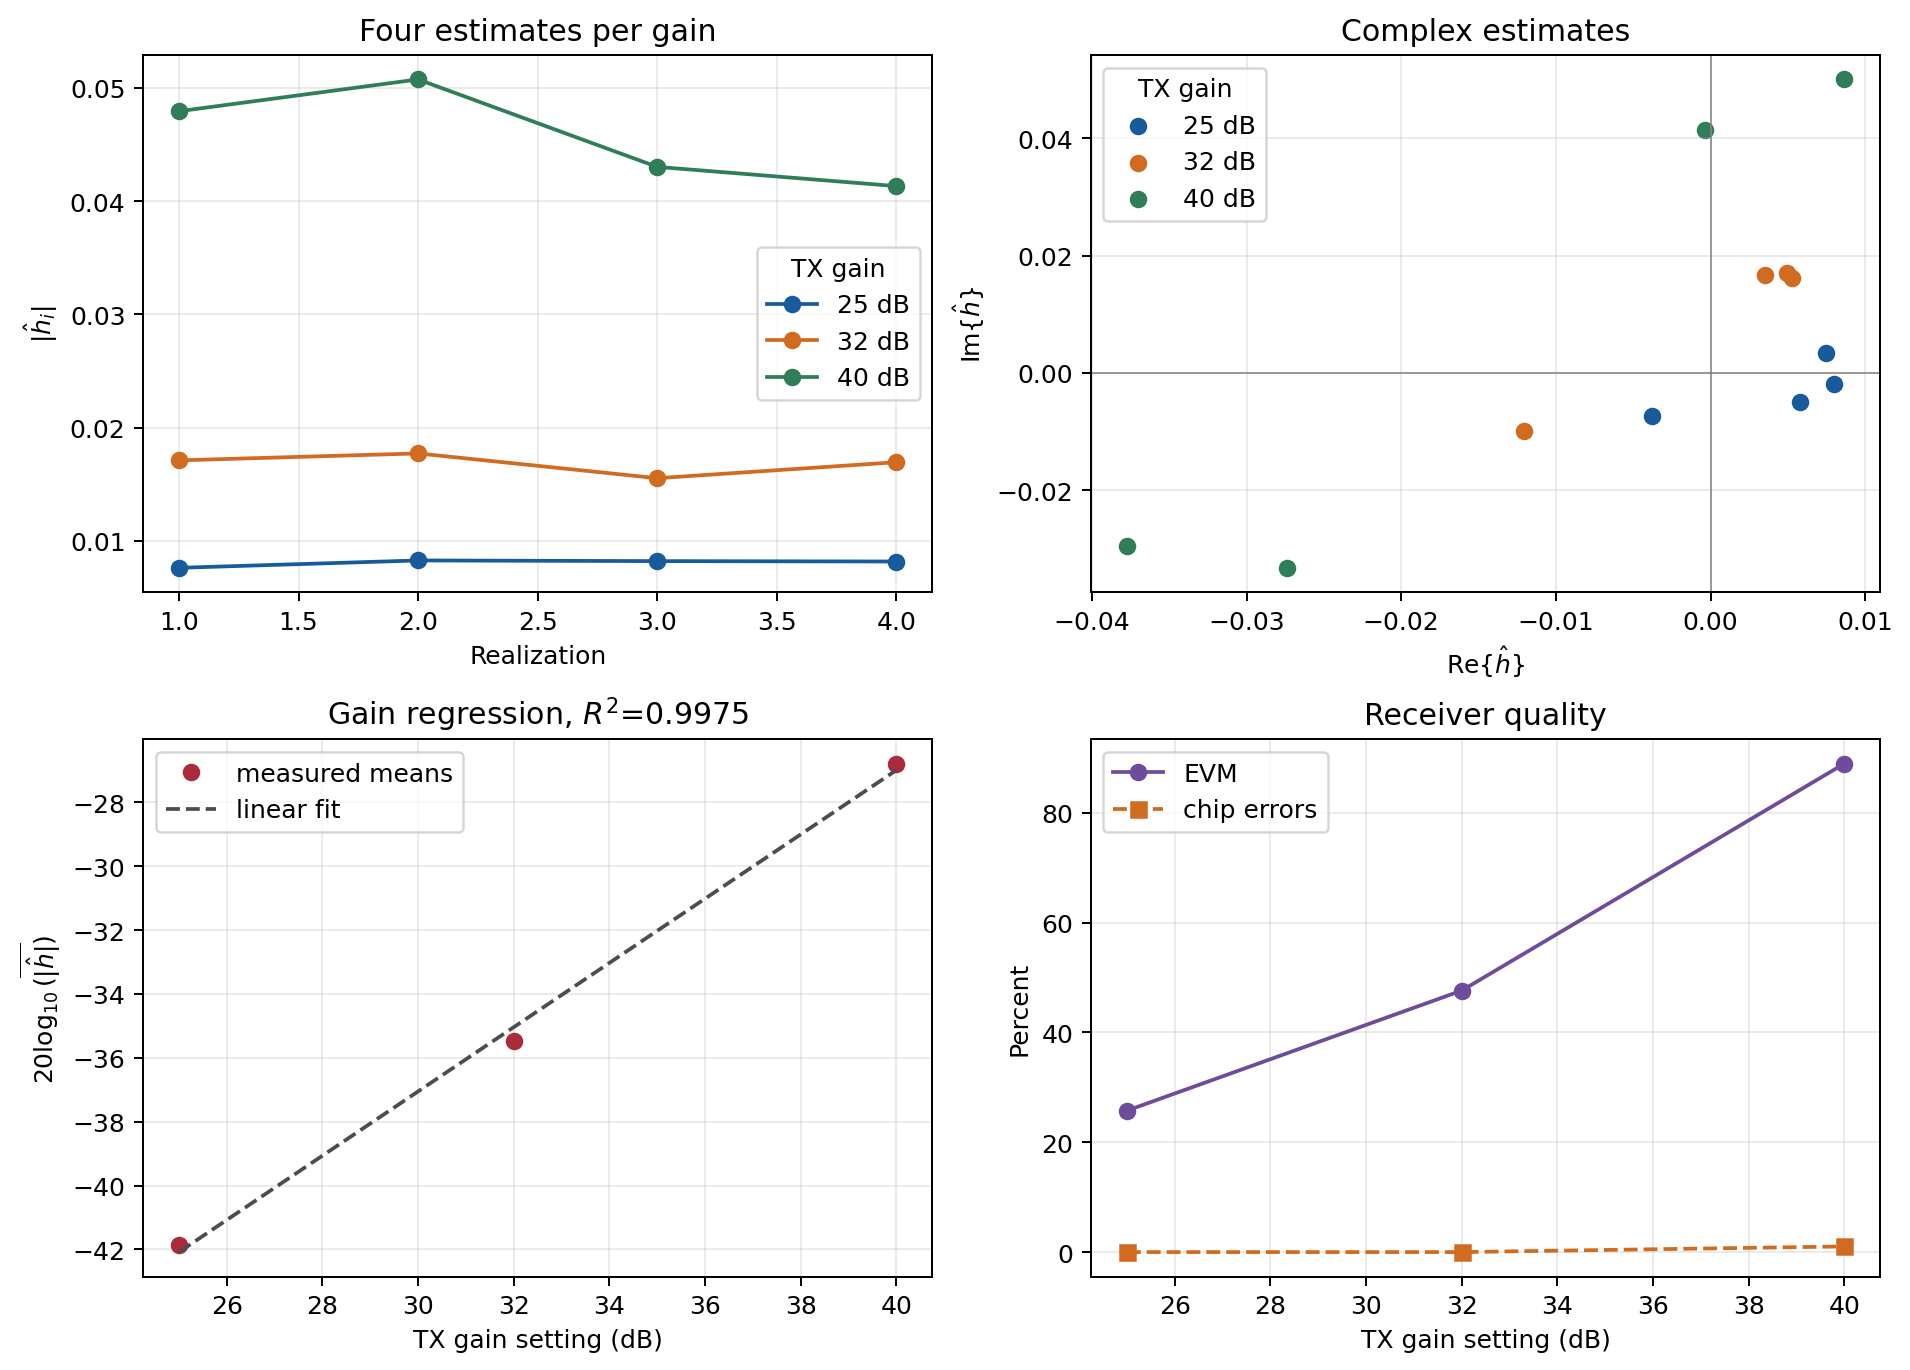

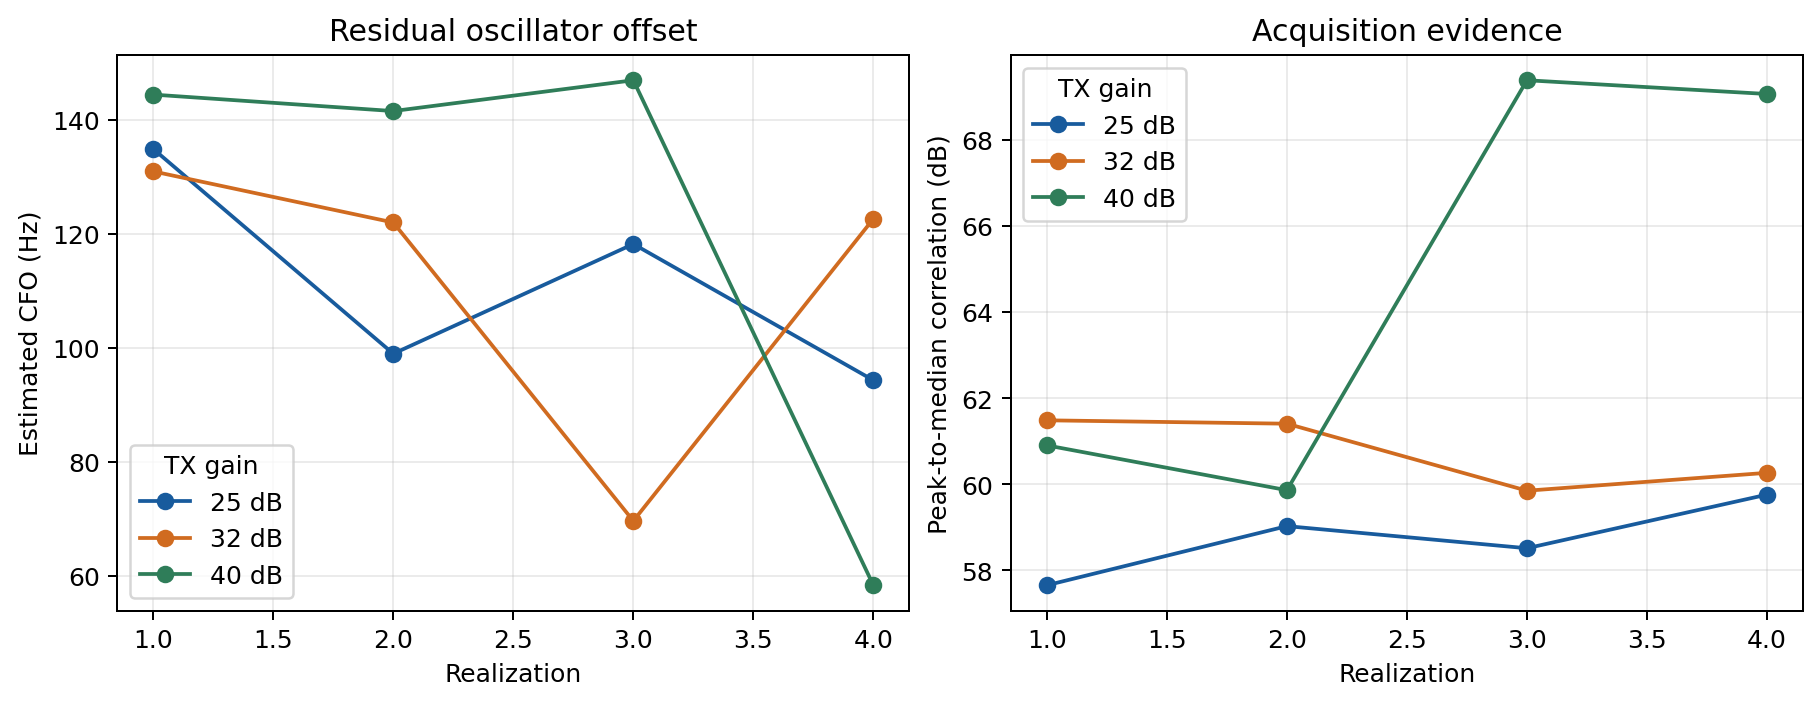

In [16]:
mean_magnitudes = np.asarray([summary["mean_magnitude"] for summary in result["summaries"]])
mean_magnitudes_db = 20*np.log10(mean_magnitudes)

# Compare the high and low conditions and fit all three points.
strength_factor = mean_magnitudes[-1] / mean_magnitudes[0]
strength_factor_db = 20 * np.log10(strength_factor)

x = np.asarray([summary["tx_gain_db"] for summary in result["summaries"]])
regression_coefficient = np.polyfit(x, mean_magnitudes_db, 1)
regression_prediction_db = np.polyval(regression_coefficient, x)
regression_residuals_db = mean_magnitudes_db - regression_prediction_db

assert np.allclose(regression_coefficient, result["regression_coefficient"])

print("strength factor, linear and dB:", strength_factor, strength_factor_db)
print("slope and intercept:", regression_coefficient)
print("residuals (dB):", regression_residuals_db)
print("R squared:", result["regression_r_squared"])

for path in plot_gain_sweep(result, FIGURE_DIR):
    display(Image(filename=path))

<span style="color:#165696"><b>Report.</b> State every parameter held fixed and label TX gain as a controlled link-strength proxy. </span>

The RX gain, center frequency, sample rate, radio pair, antenna arrangement, PN waveform, and receiver processing were held fixed across all measurements. Only the TX gain was varied between 25, 32, and 40 dB, providing a controlled and repeatable way to change the strength of the received link. Therefore, TX gain was used as a controlled link-strength proxy, meaning it represents intentional changes in link strength while the rest of the setup remains unchanged. It is only a proxy for link strength and does not represent a change in physical distance.

<span style="color:#165696"><b>Report.</b> Interpret the gain, frequency, and distance or proxy results without claiming that
normalized values are calibrated power. </span>

A fixed-rack setup was used, so the TX and RX positions remained unchanged and TX gain served as the controlled link-strength proxy. As TX gain increased from 25 to 32 to 40 dB, the mean channel magnitude increased from 0.00808 to 0.01684 to 0.04576, showing a clear increase in the measured end-to-end link strength. Because the radio positions were fixed, these results represent the effect of changing TX gain rather than changing physical distance. The measured channel magnitudes are normalized end-to-end coefficients that include the radio gains, antennas, propagation, and receiver scaling, so they should not be interpreted as calibrated received power or path loss. A frequency comparison was not performed because measurements were only conducted at 2.45 GHz with the assigned configuration because the second band 5.8 GHz was not approved.

# Conclusion

<span style="color:#165696"><b>Report.</b> The report must include a statement
connecting timing recovery, phase correction, known training, least squares, and equalization. </span>

Overall, this lab demonstrated how several receiver operations work together to reliably recover transmitted data. Timing recovery first aligns the receiver with the correct sampling instant so that symbols can be observed with minimal interference from neighboring symbols. Once timing is established, known training symbols and pilots provide references for identifying and correcting phase errors and other channel effects. These known symbols allow the receiver to use least-squares estimation to determine the complex channel coefficient h^\hat{h}h^, which captures the link’s amplitude scaling and phase shift. The resulting estimate is then used for equalization, where the received symbols are compensated for the estimated channel distortion. After equalization, the symbols move closer to their expected constellation locations, making correct detection more reliable. Together, timing recovery, phase correction, known training, least-squares estimation, and equalization form a connected process that progressively removes impairments from the received signal.